# Лабораторная работа 1. BPE и Unigram токенизаторы с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и токенизация

**Цель.** Понять токенизацию как задачу сжатия и оценить, как выбор токенизатора влияет на последующую модель.

**Что нужно сдать:**
1. Реализацию byte-level BPE и Unigram LM токенизаторов без сторонних библиотек (кроме `re`, `collections`, `math`).
2. Тесты корректности: \(\mathrm{decode}(\mathrm{encode}(x)) = x\) на всём корпусе и на произвольных байтах.
3. Сравнение с `sentencepiece` (совпадение сегментаций, скорость).
4. Графики «размер словаря — степень сжатия» для русского и английского корпусов и ответы на вопросы.

**Теория, которую нужно уметь воспроизвести на защите.** BPE — жадный алгоритм сжатия: на каждом шаге в словарь добавляется пара символов с наибольшей частотой. Unigram LM задаёт вероятностную модель сегментации
\[
p(x) = \sum_{s \in S(x)} \prod_{i} p(s_i),
\]
где \(S(x)\) — множество разбиений строки на подслова. Параметры оцениваются EM-алгоритмом: E-шаг вычисляет ожидаемые числа вхождений подслов через прямой и обратный проход (forward-backward), M-шаг нормирует их. Кодирование — поиск самой вероятной сегментации алгоритмом Витерби.

In [7]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные

Используем два корпуса: англоязычный (Tiny Shakespeare) и русскоязычный («Война и мир»). В режиме `FAST_DEV_RUN` корпуса обрезаются.

In [8]:
en_text = load_shakespeare()
ru_text = load_russian()
LIMIT = 200_000 if FAST_DEV_RUN else 2_000_000
en_text, ru_text = en_text[:LIMIT], ru_text[:LIMIT]
print(len(en_text), len(ru_text))
print(ru_text[5000:5300])

200000 200000
ступом согласие прусского короля. Вы так красноречивы. Вы дадите мне чаю?
- Сейчас. A propos,- прибавила она, опять успокоиваясь,- нынче у меня два очень интересные человека,  le vicomte de Mortemart, il est allié aux Montmorency par les Rohans, одна из лучших фамилий Франции. Это один из хороших эм


## 1. Byte-level BPE

Алгоритм обучения:
1. Разбить текст на «предтокены» регулярным выражением (слова с ведущим пробелом, числа, пунктуация), чтобы слияния не пересекали границы слов.
2. Представить каждый предтокен как последовательность байтов UTF-8 (идентификаторы 0–255).
3. Повторять `vocab_size - 256` раз: найти самую частую соседнюю пару, создать новый токен, заменить все вхождения пары.

Наивный пересчёт всех пар на каждом шаге стоит \(O(\text{корпус})\), поэтому храните счётчики пар и индекс «пара → предтокены, где она встречается», обновляя их только для затронутых предтокенов.

In [9]:
import re
from collections import Counter, defaultdict

PRETOKEN_RE = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+", re.UNICODE)

def pretokenize(text):
    return PRETOKEN_RE.findall(text)

assert "".join(pretokenize("Hello, мир! 12345  x")) == "Hello, мир! 12345  x"
print(pretokenize("Hello, мир! 12345  x"))

['Hello', ',', ' мир', '!', ' 123', '45', ' ', ' x']


In [10]:
def merge_word(word, pair, new_id):
    """Заменяет все вхождения pair в кортеже word на new_id (слева направо, без перекрытий)."""
    # TODO: ваш код
    result = []
    i = 0

    while i < len(word):
        if i + 1 < len(word) and (word[i], word[i + 1]) == pair:
            result.append(new_id)
            i += 2
        else:
            result.append(word[i])
            i += 1

    return tuple(result)

# assert merge_word((1, 2, 3, 1, 2), (1, 2), 9) == (9, 3, 9)
merge_word((1, 2, 3, 1, 2), (1, 2), 9)
# assert merge_word((1, 1, 1), (1, 1), 7) == (7, 1)

(9, 3, 9)

In [11]:
class ByteBPE:
    def __init__(self):
        self.merges = {}                       # (a, b) -> new_id, порядок вставки = ранг
        self.vocab = {i: bytes([i]) for i in range(256)}
        self._cache = {}

    def train(self, text, vocab_size, verbose=False):
        assert vocab_size >= 256
        words = Counter(tuple(t.encode("utf-8")) for t in pretokenize(text))
        word_list = list(words.keys()); counts = [words[w] for w in word_list]
        # TODO: ваш код (счётчик пар + индекс pair -> множество номеров слов, инкрементальное обновление)

        pair_counts = Counter()
        pair_words = defaultdict(set)

        # Начальный подсчёт пар
        for i, word in enumerate(word_list):
            for pair in zip(word, word[1:]):
                pair_counts[pair] += counts[i]
                pair_words[pair].add(i)

        # Обучение
        for _ in range(vocab_size - 256):
            if not pair_counts:
                break

            pair = max(pair_counts, key=pair_counts.get)
            new_id = max(self.vocab) + 1
            affected = list(pair_words[pair])

            self.merges[pair] = new_id
            self.vocab[new_id] = (
                self.vocab[pair[0]] + self.vocab[pair[1]]
            )

            # Убираем старые пары затронутых слов
            for i in affected:
                word = word_list[i]
                for p, n in Counter(zip(word, word[1:])).items():
                    pair_counts[p] -= counts[i] * n
                    pair_words[p].discard(i)
                    if pair_counts[p] <= 0:
                        del pair_counts[p]
                    if not pair_words[p]:
                        del pair_words[p]

            # Объединяем пару и добавляем новые пары
            for i in affected:
                word_list[i] = merge_word(word_list[i], pair, new_id)
                for p in zip(word_list[i], word_list[i][1:]):
                    pair_counts[p] += counts[i]
                    pair_words[p].add(i)

            if verbose:
                print(f"{pair} -> {new_id}")

        self._cache = {}
        return self

    def _encode_chunk(self, chunk):
        if chunk in self._cache: return self._cache[chunk]
        ids = tuple(chunk.encode("utf-8"))
        # TODO: ваш код (применяйте слияния в порядке их ранга (номера), пока есть применимые пары)
        for pair, new_id in self.merges.items():
            ids = merge_word(ids, pair, new_id)

        self._cache[chunk] = list(ids)
        return list(ids)

    def encode(self, text):
        out = []
        for ch in pretokenize(text): out.extend(self._encode_chunk(ch))
        return out

    def decode(self, ids):
        # TODO: ваш код
        data = b"".join(self.vocab[token_id] for token_id in ids)
        return data.decode("utf-8")


t0 = time.time()
bpe_en = ByteBPE().train(en_text, 1000)
print(f"обучение: {time.time() - t0:.1f} c, токенов в словаре: {len(bpe_en.vocab)}")
print([bpe_en.vocab[i] for i in list(bpe_en.vocab)[256:276]])

обучение: 0.3 c, токенов в словаре: 1000
[b' t', b'he', b'ou', b' a', b' s', b' w', b're', b'ha', b' the', b'in', b' m', b'nd', b' b', b'er', b'it', b'is', b'or', b'on', b'll', b'es']


### Тесты корректности

Проверьте обратимость на всём корпусе, на тексте на другом языке, на эмодзи и на случайных байтах, декодированных как UTF-8 с заменой.

In [12]:
def check_roundtrip(tok, text):
    return tok.decode(tok.encode(text)) == text

assert check_roundtrip(bpe_en, en_text)
assert check_roundtrip(bpe_en, ru_text[:20000])
assert check_roundtrip(bpe_en, "Ёжик 🦔 и 数学 — test\t\n  ")
rnd = bytes(np.random.randint(0, 256, 5000).tolist()).decode("utf-8", errors="replace")
assert check_roundtrip(bpe_en, rnd)
print("Все тесты обратимости пройдены")

Все тесты обратимости пройдены


## 2. Unigram LM токенизатор

Работаем на уровне символов Unicode, пробел заменяем на `▁` и присоединяем к началу слова (как в SentencePiece).

1. **Начальный словарь:** все символы корпуса + самые частые подстроки длины 2…`max_len` (в несколько раз больше целевого размера).
2. **E-шаг:** для каждого слова прямой проход \(\alpha_j = \log\sum_{i<j} \exp(\alpha_i + \log p(x_{i:j}))\), обратный проход \(\beta\); ожидаемое число вхождений подслова \(x_{i:j}\) — \(\exp(\alpha_i + \log p(x_{i:j}) + \beta_j - \log Z)\), умноженное на частоту слова.
3. **M-шаг:** \(p(s) \propto \mathbb{E}[\text{count}(s)]\).
4. **Прунинг:** удалить долю подслов с наименьшей вероятностью (одиночные символы не удалять), повторять до целевого размера словаря.

Это упрощённая версия: SentencePiece удаляет подслова по приросту правдоподобия корпуса при их удалении, а не по вероятности.

In [17]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log(math.exp(a - m) + math.exp(b - m))

def words_of(text):
    return Counter("▁" + w for w in text.split())

class UnigramTokenizer:
    def __init__(self, max_len=8):
        self.max_len = max_len; self.logp = {}

    def _forward_backward(self, w):
        """Возвращает (logZ, словарь ожидаемых вхождений подслов) для одного слова."""
        n = len(w)
        # TODO: ваш код
        # Прямой проход
        alpha = [-math.inf] * (n + 1)
        alpha[0] = 0.0

        for j in range(1, n + 1):
            for i in range(j):
                s = w[i:j]
                if s in self.logp:
                    alpha[j] = logsumexp2(
                        alpha[j],
                        alpha[i] + self.logp[s]
                    )

        logZ = alpha[n]

        # Обратный проход
        beta = [-math.inf] * (n + 1)
        beta[n] = 0.0

        for i in range(n - 1, -1, -1):
            for j in range(i + 1, n + 1):
                s = w[i:j]
                if s in self.logp:
                    beta[i] = logsumexp2(
                        beta[i],
                        self.logp[s] + beta[j]
                    )

        # Ожидаемые количества вхождений подслов
        expected = Counter()

        for i in range(n):
            for j in range(i + 1, n + 1):
                s = w[i:j]
                if s in self.logp:
                    q = math.exp(
                        alpha[i] + self.logp[s] + beta[j] - logZ
                    )
                    expected[s] += q

        return logZ, expected

    def train(self, text, vocab_size, init_factor=4, prune_frac=0.2, em_iters=2, verbose=True):
        words = words_of(text)
        chars = Counter(); subs = Counter()
        for w, c in words.items():
            for ch in w: chars[ch] += c
            for i in range(len(w)):
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        init = dict(chars); init.update(dict(subs.most_common(init_factor * vocab_size)))
        total = sum(init.values()); self.logp = {s: math.log(c / total) for s, c in init.items()}
        self.chars = set(chars)
        while True:
            for _ in range(em_iters):
                # TODO: ваш код (E-шаг по всем словам с весом частоты, затем M-шаг; накопите log-правдоподобие)
                expected_total = Counter()
                ll = 0.0

                # E-шаг
                for w, c in words.items():
                    logZ, expected = self._forward_backward(w)

                    ll += c * logZ

                    for s, count in expected.items():
                        expected_total[s] += c * count

                # M-шаг
                total = sum(expected_total.values())

                self.logp = {
                    s: math.log(count / total)
                    for s, count in expected_total.items()
                    if count > 0
                }

            if verbose: print(f"|V|={len(self.logp):6d}  log-likelihood={ll:.4e}")
            if len(self.logp) <= vocab_size: break
            # TODO: ваш код (удалите prune_frac наименее вероятных подслов длины > 1, не опускаясь ниже vocab_size)
            removable = [
                s for s in self.logp
                if len(s) > 1 and s not in self.chars
            ]

            n_remove = min(
                len(removable),
                len(self.logp) - vocab_size,
                max(1, int(len(self.logp) * prune_frac))
            )

            to_remove = sorted(
                removable,
                key=lambda s: self.logp[s]
            )[:n_remove]

            for s in to_remove:
                del self.logp[s]
            return self

    def segment(self, w):
        """Витерби: самая вероятная сегментация слова."""
        n = len(w)
        # TODO: ваш код
        dp = [-math.inf] * (n + 1)
        prev = [None] * (n + 1)
        dp[0] = 0.0

        for j in range(1, n + 1):
            for i in range(j):
                s = w[i:j]

                if s in self.logp:
                    score = dp[i] + self.logp[s]
                elif j == i + 1:
                    # Неизвестный символ: используем штраф за OOV
                    score = dp[i] + math.log(1e-8)
                else:
                    continue

                if score > dp[j]:
                    dp[j] = score
                    prev[j] = (i, s)

        # Восстанавливаем лучшую сегментацию с конца
        pieces = []
        j = n

        while j > 0:
            if prev[j] is None:
                raise ValueError(f"Невозможно сегментировать: {w!r}")

            i, s = prev[j]
            pieces.append(s)
            j = i

        pieces.reverse()
        return pieces

    def encode(self, text):
        # Сохраняем точную обратимость: пробельные символы кодируются отдельными «токенами»
        out = []
        for part in re.split(r"(\s+)", text):
            if not part: continue
            if part.isspace():
                if part == " ": continue           # одиночный пробел кодируется префиксом ▁ следующего слова
                out.append(part)
            else:
                out.extend(self.segment("▁" + part))
        return out

    def decode(self, pieces):
        s, prev_ws = "", True
        for p in pieces:
            if p.startswith("▁"):
                s += ("" if prev_ws else " ") + p[1:]; prev_ws = False
            else:
                s += p; prev_ws = p.isspace()
        return s

t0 = time.time()
uni_en = UnigramTokenizer().train(en_text[: (60_000 if FAST_DEV_RUN else 500_000)], 1000)
print(f"обучение: {time.time() - t0:.1f} c")
print(uni_en.encode("To be, or not to be: that is the question."))

|V|=  4058  log-likelihood=-1.1196e+05
обучение: 0.3 c
['▁To', '▁be', ',', '▁or', '▁not', '▁to', '▁be', ':', '▁that', '▁is', '▁the', '▁qu', 'es', 'tion.']


**Замечание об обратимости.** Наш Unigram-токенизатор работает с токенами-строками, а не с байтами. Обратимость гарантирована для текстов из одиночных пробелов между словами; проверьте её на корпусе, нормализованном так, как это делает SentencePiece (подряд идущие пробелы сжаты, переводы строк сохранены).

In [18]:
def normalize_spaces(t):
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r" *\n *", "\n", t).strip()

sample = normalize_spaces(en_text[:20000])
assert uni_en.decode(uni_en.encode(sample)) == sample
print("Unigram: обратимость на нормализованном корпусе выполнена")

Unigram: обратимость на нормализованном корпусе выполнена


## 3. Сравнение с SentencePiece

Обучите `sentencepiece` в режимах `bpe` и `unigram` с тем же размером словаря и сравните:
- долю слов, сегментированных одинаково с вашей реализацией;
- среднее число токенов на слово;
- время обучения и кодирования.

Полного совпадения ожидать не нужно: SentencePiece использует другой прунинг, нормализацию и обработку редких символов.

In [19]:
try:
    import sentencepiece as spm
except ImportError:
    os.system("pip -q install sentencepiece"); import sentencepiece as spm

corpus_file = DATA / "en_corpus.txt"; corpus_file.write_text(en_text, encoding="utf-8")
spm_models = {}
for mtype in ("bpe", "unigram"):
    t0 = time.time()
    spm.SentencePieceTrainer.train(input=str(corpus_file), model_prefix=str(ARTIFACTS / f"spm_{mtype}"),
                                   vocab_size=1000, model_type=mtype, character_coverage=1.0,
                                   max_sentence_length=100000, minloglevel=2)
    spm_models[mtype] = spm.SentencePieceProcessor(model_file=str(ARTIFACTS / f"spm_{mtype}.model"))
    print(mtype, f"обучение {time.time() - t0:.1f} c")

bpe обучение 0.1 c
unigram обучение 0.4 c


In [20]:
def agreement(seg_a, seg_b, words):
    same = sum(seg_a(w) == seg_b(w) for w in words)
    return same / len(words)

test_words = [w for w, _ in words_of(en_text[150_000:]).most_common(2000)]
ours_uni = lambda w: uni_en.segment(w)
sp_uni = lambda w: [p for p in spm_models["unigram"].encode(w[1:], out_type=str)]
ours_bpe = lambda w: [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(" " + w[1:])]
sp_bpe = lambda w: [p.replace("▁", " ") for p in spm_models["bpe"].encode(w[1:], out_type=str)]

# TODO: ваш код (посчитайте agreement, токены на слово и время кодирования для четырёх токенизаторов)
# Сравнение совпадения сегментации
print("Agreement:")
print("Unigram:", agreement(ours_uni, sp_uni, test_words))
print("BPE:    ", agreement(ours_bpe, sp_bpe, test_words))


# Все четыре токенизатора
tokenizers = {
    "Our Unigram": ours_uni,
    "SentencePiece Unigram": sp_uni,
    "Our BPE": ours_bpe,
    "SentencePiece BPE": sp_bpe,
}

# Среднее количество токенов и время кодирования
print("\nEncoding:")
for name, tokenizer in tokenizers.items():
    t0 = time.perf_counter()

    encoded = [tokenizer(w) for w in test_words]

    elapsed = time.perf_counter() - t0
    avg_tokens = sum(len(tokens) for tokens in encoded) / len(encoded)

    print(f"{name:25} | "
          f"токенов на слово: {avg_tokens:.2f} | "
          f"время: {elapsed:.4f} с")

Agreement:
Unigram: 0.316
BPE:     0.7275

Encoding:
Our Unigram               | токенов на слово: 2.55 | время: 0.0117 с
SentencePiece Unigram     | токенов на слово: 2.92 | время: 0.0057 с
Our BPE                   | токенов на слово: 3.15 | время: 0.0032 с
SentencePiece BPE         | токенов на слово: 2.87 | время: 0.0067 с


Выводы сравнения методов:
1. BPE показал более высокое совпадение с SentencePiece, чем Unigram (72,75% против 31,6%). Это может объясняться более детерминированным характером BPE.
2. Количество токенов на слово различается: наш Unigram использует меньше токенов, чем SentencePiece, тогда как наш BPE — больше.
3. Самой быстрой оказалась реализация BPE, самой медленной — наша реализация Unigram — скорость зависит не только от выбранного алгоритма, но и от конкретной реализации.

In [21]:
unknown_words = [
    w for w in test_words
    if any(ch not in uni_en.chars for ch in w)
]

print("Слов с неизвестными символами:", len(unknown_words))
print("Доля:", len(unknown_words) / len(test_words))

Слов с неизвестными символами: 4
Доля: 0.002


## 4. Размер словаря, язык и степень сжатия

Для словарей 1k, 8k, 32k (в `FAST_DEV_RUN`: 300, 1000, 2000) обучите BPE на английском и русском корпусах и измерьте на отложенной части:
- **fertility** — среднее число токенов на слово;
- **сжатие** — байтов UTF-8 на токен;
- **долю редких токенов** — долю токенов словаря, встретившихся в отложенной части менее 5 раз.

Обучающая и отложенная части не должны пересекаться.

In [22]:
VOCABS = [300, 1000, 2000] if FAST_DEV_RUN else [1000, 8000, 32000]

def tokenizer_stats(tok, text, vocab_size):
    # TODO: ваш код
    # Токенизируем весь текст
    ids = tok.encode(text)

    # 1. Fertility: среднее количество токенов на слово
    words = pretokenize(text)
    fertility = sum(len(tok._encode_chunk(w)) for w in words) / len(words)

    # 2. Байтов UTF-8 на токен
    bytes_per_token = len(text.encode("utf-8")) / len(ids)

    # 3. Доля редких токенов
    token_counts = Counter(ids)

    rare_tokens = sum(
        1 for token_id in range(vocab_size)
        if token_counts[token_id] < 5
    )

    rare_share = rare_tokens / vocab_size

    return {
        "fertility": fertility,
        "bytes_per_token": bytes_per_token,
        "rare_share": rare_share
    }

results = {}
for lang, text in [("en", en_text), ("ru", ru_text)]:
    cut = int(0.8 * len(text)); train_t, test_t = text[:cut], text[cut:]
    for V in VOCABS:
        tok = ByteBPE().train(train_t, V)
        results[(lang, V)] = tokenizer_stats(tok, test_t, len(tok.vocab))
        print(lang, V, {k: round(v, 3) for k, v in results[(lang, V)].items()})

en 300 {'fertility': 2.748, 'bytes_per_token': 1.371, 'rare_share': 0.657}
en 1000 {'fertility': 1.695, 'bytes_per_token': 2.223, 'rare_share': 0.476}
en 2000 {'fertility': 1.426, 'bytes_per_token': 2.643, 'rare_share': 0.725}
ru 300 {'fertility': 4.381, 'bytes_per_token': 1.942, 'rare_share': 0.557}
ru 1000 {'fertility': 2.196, 'bytes_per_token': 3.875, 'rare_share': 0.394}
ru 2000 {'fertility': 1.813, 'bytes_per_token': 4.693, 'rare_share': 0.639}


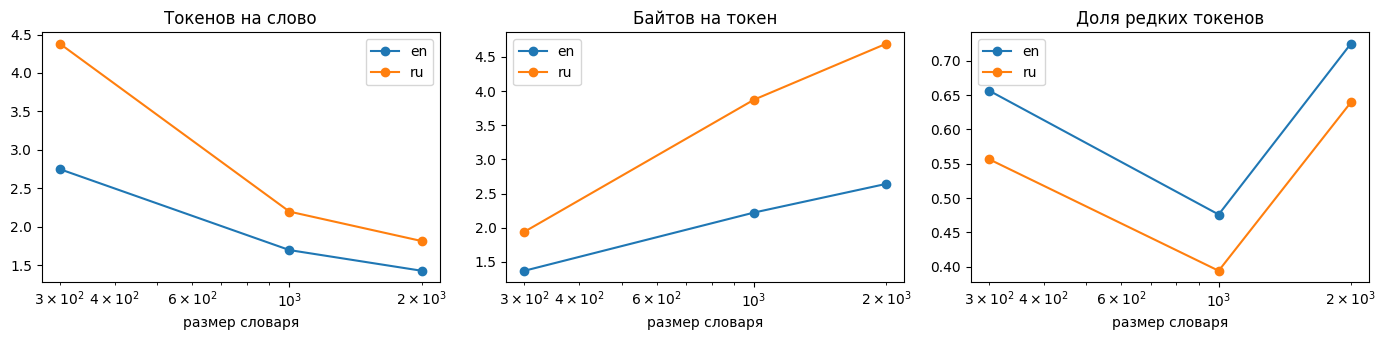

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["fertility", "bytes_per_token", "rare_share"],
                          ["Токенов на слово", "Байтов на токен", "Доля редких токенов"]):
    for lang in ("en", "ru"):
        ax.plot(VOCABS, [results[(lang, V)][key] for V in VOCABS], "o-", label=lang)
    ax.set_xscale("log"); ax.set_xlabel("размер словаря"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab01_vocab_curves.png", dpi=120); plt.show()

## 5. Токенизация чисел и кода

Посмотрите, как токенизатор разбивает числа разной длины и фрагменты кода. Найдите примеры, где одно и то же число разбивается по-разному в зависимости от контекста (с пробелом и без), и объясните, почему это мешает модели выполнять арифметику.

In [24]:
examples = ["12345 + 67890 = 80235", "x12345", " 1000000", "3.14159", "def f(x):\n    return x**2"]
for e in examples:
    print(repr(e), "->", [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(e)])

'12345 + 67890 = 80235' -> ['1', '2', '3', '4', '5', ' ', '+', ' ', '6', '7', '8', '9', '0', ' ', '=', ' ', '8', '0', '2', '3', '5']
'x12345' -> ['x', '1', '2', '3', '4', '5']
' 1000000' -> [' ', '1', '0', '0', '0', '0', '0', '0']
'3.14159' -> ['3', '.', '1', '4', '1', '5', '9']
'def f(x):\n    return x**2' -> ['de', 'f', ' f', '(', 'x', ')', ':', '\n', ' ', ' ', ' ', ' re', 't', 'urn', ' ', 'x', '*', '*', '2']


BPE разбивает числа на отдельные цифры, не объединяя их в более крупные числовые токены. Некоторые последовательности символов, например части ключевых слов def и return, объединяются в токены, при этом синтаксическое значение элементов не учитывается. ТЕряется математическая структура

## Вопросы

1. Почему BPE-обучение можно рассматривать как жадный алгоритм сжатия? Что он оптимизирует на каждом шаге и почему результат не оптимален глобально?
2. Почему при одинаковом размере словаря русский текст даёт больше токенов на слово, чем английский? Как это влияет на стоимость инференса и эффективную длину контекста?
3. Чем Unigram LM лучше BPE с вероятностной точки зрения? Что даёт возможность сэмплировать сегментации (subword regularization)?
4. Почему perplexity моделей с разными токенизаторами нельзя сравнивать напрямую и как перейти к bits-per-byte?
5. Предложите способ токенизации чисел, облегчающий арифметику, и обоснуйте его.